In [ ]:
!python3 extract_esm2_projector_emb_allTCR12_adata.py \
    --input_dir "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/processed_data/classifier/six_studies/test_meng/hvg2000_by_study_6_89_genes" \
    --prefix    5_S_6Inter89_coarseLabel_withCDR3 \
    --output_dir "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/visualize_esm2_embedding_motif" \
    --drop_unmatched \
    --esm2_projector_ckpt "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/jobs/classifier/six_studies/supconloss_simCLR_extraProfileFeatures/test_oliveira/hvg2000_by_study_6_89_genes/save/dev_SixStudy_supconH_SimCLR_extraFeat_glenhvg2000_by_study_6_89_genes_unfix1_lr0.0001_lrseq0.0001_npos9_nneg120_t0.1_maxl100_simclr_wght2.0_extrafeat2-SuContinue/model_e15.pt"

# /train_5_S_6Inter89_coarseLabel_withCDR3_tokenized_data_esm2encoded.tar

Step 0: Filtering adata by reactivity_fine ...
  train_5_S_6Inter89_coarseLabel_withCDR3.h5ad: 53,434 → 6,983 cells (dropped 46,451 with reactivity_fine == '8')
  val_5_S_6Inter89_coarseLabel_withCDR3.h5ad: 6,007 → 749 cells (dropped 5,258 with reactivity_fine == '8')

Step 1: Attaching ESM2 embeddings ...
  [train] 53,434 npz files | 6,983 cells in filtered adata


In [1]:
!which python3


/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/bin/python3


In [2]:
# The above adata has been saved. Check now:

import scanpy as sc 
encoded_ad_path = '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/visualize_esm2_embedding_motif/allTCR12_esm2_projector_emb.h5ad' 
encoded_ad_path = '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/visualize_esm2_embedding_motif/allTCR12_only_esm2_projector_emb.h5ad'
encoded_ad = sc.read_h5ad(encoded_ad_path)
encoded_ad

AnnData object with n_obs × n_vars = 2863 × 89
    obs: 'reactivity_fine', 'reactivity', 'sample', 'study', 'cdr3_aa', 'split', '_concat_batch'
    obsm: 'esm2_embedding', 'esm2_projector'

In [3]:
encoded_ad.obs['reactivity_fine'].value_counts()

1    2536
2     327
Name: reactivity_fine, dtype: int64

In [4]:
encoded_ad.obs['reactivity_fine'].value_counts()

1    2536
2     327
Name: reactivity_fine, dtype: int64

In [5]:
encoded_ad.obsm['esm2_embedding'].shape

(2863, 1280)

In [6]:
encoded_ad.obsm['esm2_projector'].shape

(2863, 128)

In [21]:
import os

def write_fasta(obs_subset, cdr3_col, out_path):
    """Write obs_names as sequence headers and cdr3_aa as sequences to a fasta file."""
    written = 0
    skipped = 0
    with open(out_path, 'w') as f:
        for cell_id, row in obs_subset.iterrows():
            seq = str(row[cdr3_col]).strip()
            if seq in ('', 'nan', 'None') or pd.isna(row[cdr3_col]):
                skipped += 1
                continue
            f.write(f'>{cell_id}\n{seq}\n')
            written += 1
    print(f"  {os.path.basename(out_path)}: {written:,} sequences written, "
          f"{skipped:,} skipped (missing CDR3)")

obs = encoded_ad.obs.copy()
obs['reactivity_fine'] = obs['reactivity_fine'].astype(str)

out_dir = "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/visualize_esm2_embedding_motif"

for label in ['1', '2']:
    subset   = obs[obs['reactivity_fine'] == label]
    out_path = os.path.join(out_dir, f'cdr3_reactivityFine_{label}.fasta')
    print(f"\nReactivity '{label}': {len(subset):,} cells")
    write_fasta(subset, 'cdr3_aa', out_path)




Reactivity '1': 2,536 cells
  cdr3_reactivityFine_1.fasta: 2,536 sequences written, 0 skipped (missing CDR3)

Reactivity '2': 327 cells
  cdr3_reactivityFine_2.fasta: 327 sequences written, 0 skipped (missing CDR3)


In [22]:
out_path

'/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/visualize_esm2_embedding_motif/cdr3_reactivityFine_2.fasta'

## 20260816
## output cdr3 fasta by cancer type

In [14]:
dic_map = {}
sample_list = list(encoded_ad.obs['sample'].unique())
for x in sample_list:
    if x.startswith('TIPC'):
        dic_map[x] = 'PDAC'
    elif x.startswith('CRI'):
        dic_map[x] = 'GI'
    elif x.startswith('hanada'):
        dic_map[x] = 'NSCLC'
    elif x.startswith('oliveira'):
        dic_map[x] = 'Melanoma'
    elif x.startswith('MD') | x.startswith('NY'):
        dic_map[x] = 'NSCLC'
    elif x == 'lowery_4322':
        dic_map[x] = 'Breast'
    elif x == 'lowery_4317':
        dic_map[x]= 'Rectal'
    elif x == 'lowery_4394':
        dic_map[x]= 'Colon'
    elif x == 'lowery_4323':
        dic_map[x]= 'Rectal'
    elif x == 'lowery_4400':
        dic_map[x]= 'Colon'
    elif x == 'lowery_4324':
        dic_map[x]= 'Colon'
    elif x == 'lowery_4283':
        dic_map[x]= 'Colon'
    elif x == 'lowery_4393':
        dic_map[x]= 'Colon'
    elif x == 'lowery_4261':
        dic_map[x]= 'Melanoma'
    elif x == 'lowery_4385':
        dic_map[x]= 'Colon'
    elif x == 'lowery_4397':
        dic_map[x]= 'Anal SCC'
    elif x == 'lowery_4342_aggr':
        dic_map[x]= 'Colon'
    elif x == 'lowery_4298_aggr':
        dic_map[x]= 'Rectal'
    elif x == 'lowery_4421_aggr':
        dic_map[x]= 'Colon'

encoded_ad.obs['Cancer_type'] = encoded_ad.obs['sample'].map(dic_map)

import os

def write_fasta(obs_subset, cdr3_col, out_path):
    """Write obs_names as sequence headers and cdr3_aa as sequences to a fasta file."""
    written = 0
    skipped = 0
    with open(out_path, 'w') as f:
        for cell_id, row in obs_subset.iterrows():
            seq = str(row[cdr3_col]).strip()
            if seq in ('', 'nan', 'None') or pd.isna(row[cdr3_col]):
                skipped += 1
                continue
            f.write(f'>{cell_id}\n{seq}\n')
            written += 1
    print(f"  {os.path.basename(out_path)}: {written:,} sequences written, "
          f"{skipped:,} skipped (missing CDR3)")

encoded_1 = encoded_ad[encoded_ad.obs['reactivity_fine'] == '1'].copy()
obs = encoded_1.obs.copy()
obs['Cancer_type'] = obs['Cancer_type'].astype(str)



In [13]:
encoded_ad


AnnData object with n_obs × n_vars = 2863 × 89
    obs: 'reactivity_fine', 'reactivity', 'sample', 'study', 'cdr3_aa', 'split', '_concat_batch', 'Cancer_type'
    obsm: 'esm2_embedding', 'esm2_projector'

In [15]:
obs.shape

(2536, 8)

In [16]:
obs['Cancer_type'].value_counts()

NSCLC       2047
Rectal       232
Colon        202
GI            52
Melanoma       2
Anal SCC       1
Name: Cancer_type, dtype: int64

In [17]:
obs['Cancer_type'].unique()

array(['NSCLC', 'Rectal', 'Colon', 'GI', 'Anal SCC', 'Melanoma'],
      dtype=object)

In [18]:
import pandas as pd

out_dir = "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/visualize_esm2_embedding_motif"

for label in ['NSCLC', 'Rectal', 'Colon', 'GI']:
    subset   = obs[obs['Cancer_type'] == label]
    out_path = os.path.join(out_dir, f'cdr3_CancerType_{label}.fasta')
    print(f"\CancerType '{label}': {len(subset):,} cells")
    write_fasta(subset, 'cdr3_aa', out_path)



\CancerType 'NSCLC': 2,047 cells
  cdr3_CancerType_NSCLC.fasta: 2,047 sequences written, 0 skipped (missing CDR3)
\CancerType 'Rectal': 232 cells
  cdr3_CancerType_Rectal.fasta: 232 sequences written, 0 skipped (missing CDR3)
\CancerType 'Colon': 202 cells
  cdr3_CancerType_Colon.fasta: 202 sequences written, 0 skipped (missing CDR3)
\CancerType 'GI': 52 cells
  cdr3_CancerType_GI.fasta: 52 sequences written, 0 skipped (missing CDR3)


In [1]:
#!/usr/bin/env python3
"""
Visualise ESM2 TCR embeddings (t-SNE / UMAP) for train + val splits,
colour-coded by reactivity, and plot CDR3 sequence logos for reactive cells.

Usage
-----
python visualize_esm2_embedding_motif.py \
    --input_dir /path/to/data \
    --prefix    5_S_6Inter89_coarseLabel_withCDR3 \
    --output_dir /path/to/output

Expected layout inside --input_dir:
    train_<prefix>_tokenized_data_esm2encoded/   ← one *.npz per cell
    train_<prefix>.h5ad                          ← obs['reactivity']
    val_<prefix>_tokenized_data_esm2encoded/
    val_<prefix>.h5ad

NPZ key discovery is automatic; mean-pooling is applied if the array is 2-D
(sequence_length × embed_dim → embed_dim).

Cell ID mapping: npz stem with the last '-...' suffix stripped
    e.g.  "ACGT_TRA_CASSXXXX-1.npz"  →  cell_id = "ACGT_TRA_CASSXXXX"
"""

import os
import sys
import glob
import argparse
import warnings
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')

# ── Optional imports ────────────────────────────────────────────────────────
try:
    import umap as umap_lib
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
    print('[WARN] umap-learn not installed — UMAP plot will be skipped. '
          'Install with: pip install umap-learn')

try:
    import logomaker
    HAS_LOGO = True
except ImportError:
    HAS_LOGO = False
    print('[WARN] logomaker not installed — motif logo uses information-content bar chart. '
          'Install with: pip install logomaker')

In [ ]:



# ── Constants ───────────────────────────────────────────────────────────────
COLORS  = {0: '#5688C7', 1: '#E8704A'}
LABELS  = {0: 'Non-reactive', 1: 'Reactive'}
MARKERS = {'train': 'o', 'val': '^'}

CDR3_COL_CANDIDATES = [
    'IR_VDJ_1_junction_aa', 'IR_VJ_1_junction_aa',   # scirpy / AIRR
    'CDR3_beta', 'CDR3_alpha',
    'CDR3_b',    'CDR3_a',
    'cdr3_b',    'cdr3_a',
    'cdr3_TRB',  'cdr3_TRA',
    'TRB_CDR3',  'TRA_CDR3',
    'junction_aa',
]


# ── Embedding loading ────────────────────────────────────────────────────────

def _extract_embedding(npz_data):
    """
    Extract a 1-D float32 vector from an open NpzFile.
    Tries common ESM2 key names first, then falls back to the first usable array.
    If the array is 2-D (seq_len × dim), mean-pools over the sequence axis.
    """
    preferred = [
        'embedding', 'emb', 'mean_representations', 'representations',
        'esm2_embedding', 'token_representations', 'last_hidden_state',
    ]
    ordered = [k for k in preferred if k in npz_data.files] + \
              [k for k in npz_data.files if k not in preferred]

    for key in ordered:
        raw = npz_data[key]
        # Handle 0-d object arrays that wrap a dict or similar
        if raw.ndim == 0:
            try:
                raw = np.array(raw.item())
            except Exception:
                continue
        arr = np.asarray(raw, dtype=np.float32)
        if arr.ndim == 2:
            arr = arr.mean(axis=0)       # (seq_len, dim) → (dim,)
        if arr.ndim == 1 and arr.size > 0:
            return arr
    return None


def load_split(npz_dir, h5ad_path, split_label):
    """
    Load all npz embeddings for one split and attach reactivity from the h5ad.

    Returns
    -------
    embeddings : list of 1-D np.ndarray
    cell_ids   : list of str
    reactivities : list of int (0 / 1)
    splits     : list of str (all == split_label)
    obs        : pd.DataFrame  (h5ad .obs, for CDR3 lookup later)
    """
    adata = sc.read_h5ad(h5ad_path)
    react_raw = adata.obs['reactivity'].astype(str).str.strip()
    react_map = react_raw.map(
        {'1': 1, '0': 0, 'True': 1, 'False': 0,
         'reactive': 1, 'non-reactive': 0, 'Reactive': 1, 'Non-reactive': 0}
    ).to_dict()

    npz_files = sorted(glob.glob(os.path.join(npz_dir, '*.npz')))
    print(f'  [{split_label}] {len(npz_files):,} npz files | {adata.n_obs:,} cells in h5ad')

    embeddings, cell_ids, reacts, splits = [], [], [], []
    skipped_label = skipped_emb = 0

    for fpath in npz_files:
        stem    = os.path.splitext(os.path.basename(fpath))[0]
        cell_id = stem.rsplit('-', 1)[0]

        r = react_map.get(cell_id)
        if r is None:
            skipped_label += 1
            continue

        try:
            data = np.load(fpath, allow_pickle=True)
            emb  = _extract_embedding(data)
        except Exception as e:
            skipped_emb += 1
            continue

        if emb is None:
            skipped_emb += 1
            continue

        embeddings.append(emb)
        cell_ids.append(cell_id)
        reacts.append(int(r))
        splits.append(split_label)

    print(f'    loaded {len(embeddings):,}  |  '
          f'skipped: label-miss={skipped_label}, emb-fail={skipped_emb}')
    return embeddings, cell_ids, reacts, splits, adata.obs


# ── Dimensionality reduction ─────────────────────────────────────────────────

def maybe_pca(X, n_components=50):
    """Reduce to n_components with PCA if X has more dimensions."""
    if n_components and X.shape[1] > n_components:
        print(f'  PCA: {X.shape[1]} → {n_components} dims')
        pca = PCA(n_components=n_components, random_state=42)
        X = pca.fit_transform(X)
        print(f'    explained variance: {pca.explained_variance_ratio_.sum():.2%}')
    return X


# ── Plotting ─────────────────────────────────────────────────────────────────

def plot_embedding(coords, reacts, splits, method, out_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, color_by, title_sfx in zip(
            axes,
            ['reactivity', 'split'],
            ['coloured by reactivity', 'coloured by split']):

        if color_by == 'reactivity':
            for label in [0, 1]:
                mask = np.array(reacts) == label
                ax.scatter(coords[mask, 0], coords[mask, 1],
                           c=COLORS[label], label=LABELS[label],
                           s=5, alpha=0.45, linewidths=0, rasterized=True)
        else:
            split_colors = {'train': '#4C72B0', 'val': '#DD8452'}
            for sp in sorted(set(splits)):
                mask = np.array(splits) == sp
                ax.scatter(coords[mask, 0], coords[mask, 1],
                           c=split_colors.get(sp, 'grey'), label=sp,
                           marker=MARKERS.get(sp, 'o'),
                           s=5, alpha=0.45, linewidths=0, rasterized=True)

        ax.set_xlabel(f'{method}-1', fontsize=11)
        ax.set_ylabel(f'{method}-2', fontsize=11)
        ax.set_title(f'{method} of ESM2 embeddings\n{title_sfx}', fontsize=11)
        ax.legend(markerscale=3, frameon=False, fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.close()
    print(f'  Saved {os.path.basename(out_path)}')


# ── Motif / sequence logo ────────────────────────────────────────────────────

AA_LIST = list('ACDEFGHIKLMNPQRSTVWY')


def center_align(seqs, width=None):
    """Center-pad sequences with '-' to a common width."""
    seqs = [s for s in seqs if isinstance(s, str) and s not in ('', 'nan', 'None')]
    if not seqs:
        return [], 0
    if width is None:
        width = max(len(s) for s in seqs)
    out = []
    for s in seqs:
        pad  = width - len(s)
        left = pad // 2
        out.append('-' * left + s + '-' * (pad - left))
    return out, width


def make_freq_df(aligned, width):
    """Position-frequency matrix as a DataFrame (columns = amino acids + '-')."""
    cols    = AA_LIST + ['-']
    counts  = np.zeros((width, len(cols)), dtype=float)
    col_idx = {aa: i for i, aa in enumerate(cols)}
    for seq in aligned:
        for i, aa in enumerate(seq[:width]):
            if aa in col_idx:
                counts[i, col_idx[aa]] += 1
    sums = counts.sum(axis=1, keepdims=True)
    sums[sums == 0] = 1
    return pd.DataFrame(counts / sums, columns=cols)


def information_content(freq_df):
    """Bits of information per position (gap column excluded)."""
    p = freq_df[AA_LIST].values.clip(1e-9, 1)
    H = -(p * np.log2(p)).sum(axis=1)
    return np.log2(len(AA_LIST)) - H


def plot_motif(seqs, cdr3_col, n_reactive, out_path):
    aligned, width = center_align(seqs)
    if not aligned:
        print(f'  [SKIP motif] no valid sequences for {cdr3_col}')
        return

    freq_df = make_freq_df(aligned, width)
    info    = information_content(freq_df)

    if HAS_LOGO:
        # Weight each position's heights by its information content
        logo_df = freq_df[AA_LIST].multiply(info, axis=0)
        fig, ax = plt.subplots(figsize=(max(7, width * 0.55), 3.2))
        logo = logomaker.Logo(logo_df, ax=ax, color_scheme='chemistry',
                              vpad=0.05, width=0.9)
        logo.style_spines(visible=False)
        logo.style_spines(spines=['left', 'bottom'], visible=True)
        ax.set_ylabel('Bits', fontsize=10)
    else:
        fig, ax = plt.subplots(figsize=(max(7, width * 0.55), 3.2))
        ax.bar(range(width), info, color='#E8704A', width=0.8)
        ax.set_ylabel('Information (bits)', fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)

    ax.set_xlabel('Position (center-aligned)', fontsize=10)
    ax.set_xticks(range(width))
    ax.set_xticklabels([str(i + 1) for i in range(width)], fontsize=7)
    ax.set_title(
        f'Reactive T-cell CDR3 motif — {cdr3_col}\n'
        f'n = {len(aligned)} sequences  (from {n_reactive} reactive cells)',
        fontsize=11)

    plt.tight_layout()
    plt.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.close()
    print(f'  Saved {os.path.basename(out_path)}')


def plot_length_distribution(seqs_by_col, out_path):
    """Histogram of CDR3 length distribution for reactive vs all."""
    n_cols = len(seqs_by_col)
    if n_cols == 0:
        return
    fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 3.5), squeeze=False)
    for ax, (col, (react_seqs, all_seqs)) in zip(axes[0], seqs_by_col.items()):
        bins = range(5, 25)
        ax.hist([len(s) for s in all_seqs],    bins=bins, alpha=0.5,
                color='#5688C7', label='All',      density=True)
        ax.hist([len(s) for s in react_seqs], bins=bins, alpha=0.7,
                color='#E8704A', label='Reactive', density=True)
        ax.set_xlabel('CDR3 length (aa)', fontsize=10)
        ax.set_ylabel('Density',          fontsize=10)
        ax.set_title(col, fontsize=10)
        ax.legend(frameon=False, fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.close()
    print(f'  Saved {os.path.basename(out_path)}')


# ── CLI ──────────────────────────────────────────────────────────────────────

def parse_args():
    p = argparse.ArgumentParser(
        description='ESM2 embedding t-SNE/UMAP + CDR3 motif visualisation')
    p.add_argument('--input_dir',  required=True)
    p.add_argument('--prefix',     required=True,
                   help='Shared file/folder prefix, '
                        'e.g. "5_S_6Inter89_coarseLabel_withCDR3"')
    p.add_argument('--output_dir', required=True)
    p.add_argument('--pca_components', type=int, default=50,
                   help='PCA pre-reduction dimensions (0 to skip)')
    p.add_argument('--tsne_perplexity', type=float, default=40.0)
    p.add_argument('--umap_neighbors',  type=int,   default=30)
    p.add_argument('--umap_min_dist',   type=float, default=0.3)
    p.add_argument('--n_jobs',          type=int,   default=4,
                   help='Parallel jobs for t-SNE')
    p.add_argument('--random_state',    type=int,   default=42)
    p.add_argument('--motif_max_len',   type=int,   default=20,
                   help='Trim CDR3s longer than this before logo (0 = no trim)')
    return p.parse_args()


def main():
    args = parse_args()
    os.makedirs(args.output_dir, exist_ok=True)

    train_npz  = os.path.join(args.input_dir,
                              f'train_{args.prefix}_tokenized_data_esm2encoded')
    train_h5ad = os.path.join(args.input_dir, f'train_{args.prefix}.h5ad')
    val_npz    = os.path.join(args.input_dir,
                              f'val_{args.prefix}_tokenized_data_esm2encoded')
    val_h5ad   = os.path.join(args.input_dir, f'val_{args.prefix}.h5ad')

    for path in [train_npz, train_h5ad, val_npz, val_h5ad]:
        if not os.path.exists(path):
            sys.exit(f'[ERROR] not found: {path}')

    # ── Load ─────────────────────────────────────────────────────────────────
    print('Loading train embeddings ...')
    tr_emb, tr_ids, tr_react, tr_split, tr_obs = load_split(
        train_npz, train_h5ad, 'train')
    print('Loading val embeddings ...')
    va_emb, va_ids, va_react, va_split, va_obs = load_split(
        val_npz, val_h5ad, 'val')

    all_emb    = np.vstack(tr_emb + va_emb)
    all_react  = np.array(tr_react + va_react)
    all_ids    = tr_ids + va_ids
    all_splits = tr_split + va_split
    n_pos  = all_react.sum()
    n_neg  = (all_react == 0).sum()
    print(f'\nCombined: {len(all_ids):,} cells  '
          f'(reactive={n_pos:,}, non-reactive={n_neg:,})')

    if all_emb.shape[0] == 0:
        sys.exit('[ERROR] No embeddings loaded — check file paths and cell-ID mapping.')

    # ── PCA pre-reduction ────────────────────────────────────────────────────
    X = maybe_pca(all_emb, args.pca_components)
    # save the PCA for now:
    np.savez(
        os.path.join(args.output_dir, "PCA_embedding_data.npz"),
        X=X,
        all_ids=all_ids
    )

    # ── t-SNE ────────────────────────────────────────────────────────────────
    print('\nRunning t-SNE ...')
    tsne_model  = TSNE(n_components=2, perplexity=args.tsne_perplexity,
                       random_state=args.random_state, n_jobs=args.n_jobs,
                       verbose=1)
    tsne_coords = tsne_model.fit_transform(X)
    plot_embedding(tsne_coords, all_react, all_splits, 't-SNE',
                   os.path.join(args.output_dir, 'tsne_reactivity.png'))

    # ── UMAP ─────────────────────────────────────────────────────────────────
    umap_coords = None
    if HAS_UMAP:
        print('\nRunning UMAP ...')
        reducer     = umap_lib.UMAP(n_neighbors=args.umap_neighbors,
                                    min_dist=args.umap_min_dist,
                                    n_components=2,
                                    random_state=args.random_state)
        umap_coords = reducer.fit_transform(X)
        plot_embedding(umap_coords, all_react, all_splits, 'UMAP',
                       os.path.join(args.output_dir, 'umap_reactivity.png'))
    else:
        print('\n[SKIP] UMAP — install umap-learn to enable.')

    # ── Save metadata ─────────────────────────────────────────────────────────
    meta = pd.DataFrame({
        'cell_id':    all_ids,
        'reactivity': all_react,
        'split':      all_splits,
        'tsne_1':     tsne_coords[:, 0],
        'tsne_2':     tsne_coords[:, 1],
    })
    if umap_coords is not None:
        meta['umap_1'] = umap_coords[:, 0]
        meta['umap_2'] = umap_coords[:, 1]
    meta.to_csv(os.path.join(args.output_dir, 'embedding_metadata.csv'), index=False)
    print(f'\n  Saved embedding_metadata.csv  ({len(meta):,} rows)')

    # ── CDR3 motif ───────────────────────────────────────────────────────────
    print('\nBuilding CDR3 motifs for reactive cells ...')
    combined_obs = pd.concat([tr_obs, va_obs])

    reactive_ids = set(cid for cid, r in zip(all_ids, all_react) if r == 1)
    reactive_obs = combined_obs[combined_obs.index.isin(reactive_ids)]
    print(f'  {len(reactive_obs):,} reactive cells for motif analysis')

    cdr3_cols = [c for c in CDR3_COL_CANDIDATES if c in combined_obs.columns]
    if not cdr3_cols:
        print(f'  [WARN] no CDR3 columns found. '
              f'Available obs columns: {list(combined_obs.columns)}')
    else:
        len_data = {}
        for col in cdr3_cols:
            react_seqs = (reactive_obs[col].dropna().astype(str)
                          .replace({'nan': None, 'None': None})
                          .dropna().tolist())
            all_seqs   = (combined_obs[col].dropna().astype(str)
                          .replace({'nan': None, 'None': None})
                          .dropna().tolist())
            react_seqs = [s for s in react_seqs if s]
            all_seqs   = [s for s in all_seqs   if s]
            if not react_seqs:
                continue
            len_data[col] = (react_seqs, all_seqs)

            lengths = [len(s) for s in react_seqs]
            print(f'  {col}: {len(react_seqs):,} seqs, '
                  f'length {min(lengths)}–{max(lengths)} '
                  f'(median {int(np.median(lengths))})')

            # Optionally trim very long sequences before logo
            if args.motif_max_len > 0:
                react_seqs = [s for s in react_seqs if len(s) <= args.motif_max_len]

            plot_motif(react_seqs, col, len(reactive_obs),
                       os.path.join(args.output_dir, f'motif_{col}.png'))

            # Export PFM as CSV
            aligned, width = center_align(react_seqs)
            if aligned:
                pfm = make_freq_df(aligned, width)
                pfm.to_csv(os.path.join(args.output_dir, f'pfm_{col}.csv'))

        if len_data:
            plot_length_distribution(
                len_data,
                os.path.join(args.output_dir, 'cdr3_length_distribution.png'))

    print('\nDone.  Outputs in:', args.output_dir)


if __name__ == '__main__':
    main()


In [1]:
### Check the output:

import os 

out_dir = "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/visualize_esm2_embedding_motif"
print(os.listdir(out_dir))

['allTCR12_only_esm2_projector_emb_UMAP_Tsne_embedding_comparison_reactivity_fine.pdf', 'tsne_reactivity_fine_all_samples_withCDR3_1clone_highlight.pdf', 'cdr3_reactivityFine_1.fasta', 'allTCR12_only_esm2_projector_emb_umap_byCancertypeSample.pdf', 'cdr3_motif_reactive_caushi_2samples_pfm_cdr3_viral.csv', 'tsne_reactivity_fine_all_samples_withCDR3.pdf', 'PCA_embedding_data.npz', 'tsne_reactivity_fine_caushi_2samples_2clone_highlight.pdf', 'cdr3_motif_all_samples_withCDR3_motif_viral.png', 'streme_1vs2_matching_sequences.tsv', 'cdr3_motif_all_samples_withCDR3_motif_antitumor.pdf', 'cdr3_motif_all_samples_withCDR3_motif_antitumor.png', 'allTCR12_esm2_projector_emb_UMAP_Tsne_embedding_comparison_reactivity_fine.png', 'allTCR12_esm2_projector_emb.h5ad', 'tsne_reactivity.png', 'allTCR12_only_esm2_projector_emb_reactive_motif_umap_byCancerTypeSample.pdf', 'allTCR12_only_esm2_projector_emb_UMAP_Tsne_embedding_comparison_reactivity_fine.png', 'streme_1vs2_matching_sites.tsv', 'tsne_reactivity_

In [2]:
import pandas as pd 

df_meta = pd.read_csv(os.path.join(out_dir,'embedding_metadata.csv'))

### load the all the training data:


Reading: /cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/caushi_nature_neoantigen_specificTIL/rawCount_adatas_cd8/caushi_4patients_log1p.h5ad
  → 40943 cells, 12619 genes
Reading: /cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/hanada_NSCLC_CancerCell/runs/rawCount_adatas_cd8/hanada_4samples_CD8_log1p.h5ad
  → 9227 cells, 15574 genes
Reading: /cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/lowery_neoTCR_metastatic/runs/rawCount_adatas_cd8/lowery_14samples_log1p_cd0718_agree_CD8.h5ad
  → 7825 cells, 10931 genes
Reading: /cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/meng_scienceTranslationalMedicine_PDAC/rawCount_adatas_cd8/GSE254250_PDAC_9sample_CD8_RNA_expression_meta_basicQC_log1p.h5ad
  → 17855 cells, 16979 genes
Reading: /cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_co

/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


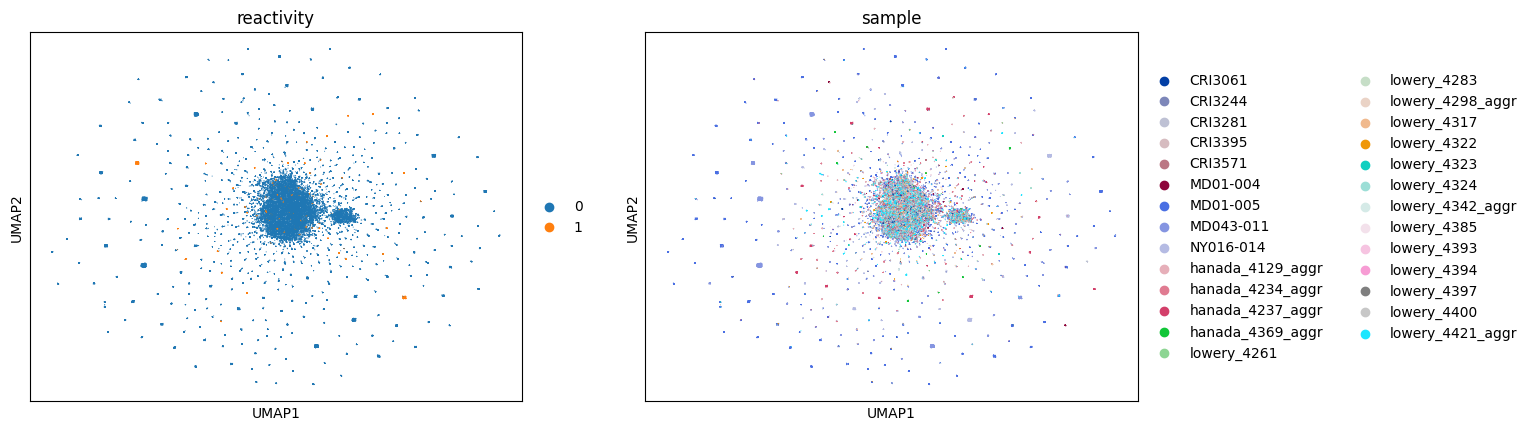

/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


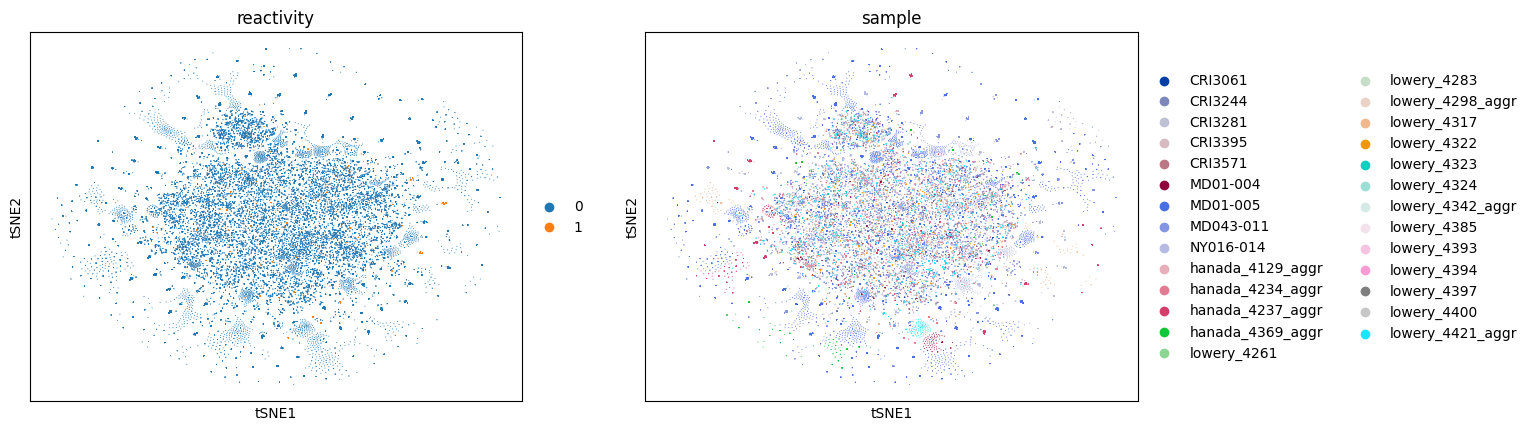

In [3]:
import scanpy as sc
import pandas as pd
import numpy as np
import anndata

# ── Step 1: Define your list of adata paths ───────────────────────────────────
adata_paths = [
    '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/caushi_nature_neoantigen_specificTIL/rawCount_adatas_cd8/caushi_4patients_log1p.h5ad',
    '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/hanada_NSCLC_CancerCell/runs/rawCount_adatas_cd8/hanada_4samples_CD8_log1p.h5ad',
    '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/lowery_neoTCR_metastatic/runs/rawCount_adatas_cd8/lowery_14samples_log1p_cd0718_agree_CD8.h5ad',
    '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/meng_scienceTranslationalMedicine_PDAC/rawCount_adatas_cd8/GSE254250_PDAC_9sample_CD8_RNA_expression_meta_basicQC_log1p.h5ad',
    '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/oliveira_melanoma_Nature/rawCount_adatas_cd8/Oliveira_log1p.h5ad',
    '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/zheng_GI_cancer_CancerCell/93cvs2z3mz-2/rawCount_adatas_cd8/zheng_5samples_log1p.h5ad'
]

# ── Step 2: Read all adatas ───────────────────────────────────────────────────
adatas = []
for path in adata_paths:
    print(f"Reading: {path}")
    ad = sc.read_h5ad(path)
    adatas.append(ad)
    print(f"  → {ad.n_obs} cells, {ad.n_vars} genes")





# ── Step 3a: Harmonize obs columns — fill missing cdr3_aa with NaN ────────────
for ad in adatas:
    if 'cdr3_aa' not in ad.obs.columns:
        ad.obs['cdr3_aa'] = np.nan
        print(f"  [INFO] 'cdr3_aa' not found, filled with NaN")
    else:
        print(f"  [INFO] 'cdr3_aa' found, {ad.obs['cdr3_aa'].notna().sum()} non-null values")

# ── Step 3: Find shared obs columns ──────────────────────────────────────────
shared_obs_cols = set(adatas[0].obs.columns)
for ad in adatas[1:]:
    shared_obs_cols &= set(ad.obs.columns)
shared_obs_cols = sorted(shared_obs_cols)
print(f"\nShared obs columns ({len(shared_obs_cols)}): {shared_obs_cols}")

# Subset each adata's obs to shared columns only before concat
for ad in adatas:
    ad.obs = ad.obs[shared_obs_cols]

# ── Step 4: Concatenate ───────────────────────────────────────────────────────
work_ob = anndata.concat(
    adatas,
    join='inner',        # keep only shared genes (vars)
    merge='same',        # keep var metadata that is identical across adatas
    label='batch',       # adds a 'batch' column to obs with the adata index
    keys=[str(i) for i in range(len(adatas))],
)
work_ob.obs_names_make_unique()

print(f"\nConcatenated work_ob: {work_ob.n_obs} cells, {work_ob.n_vars} genes")

# ── Step 4b: Filter to cells present in df_meta ───────────────────────────────
meta_cell_ids  = set(df_meta['cell_id'])
cells_to_keep  = work_ob.obs_names.isin(meta_cell_ids)

print(f"Cells in work_ob           : {work_ob.n_obs:,}")
print(f"Cells in df_meta           : {len(meta_cell_ids):,}")
print(f"Cells kept (intersection)  : {cells_to_keep.sum():,}")
print(f"Cells dropped              : {(~cells_to_keep).sum():,}")

work_ob = work_ob[cells_to_keep].copy()

# ── Step 5: Align df_meta to work_ob cell order ───────────────────────────────
meta_indexed = df_meta.set_index('cell_id')
meta_aligned  = meta_indexed.reindex(work_ob.obs_names)

# ── Step 6: Check for missing cells ──────────────────────────────────────────
for embed_cols, name in [(['tsne_1', 'tsne_2'], 'tSNE'), (['umap_1', 'umap_2'], 'UMAP')]:
    n_missing = meta_aligned[embed_cols].isna().any(axis=1).sum()
    if n_missing > 0:
        print(f"Warning: {n_missing} cells in work_ob have no matching {name} coords in df_meta")

# ── Step 7: Store embeddings in obsm ─────────────────────────────────────────
work_ob.obsm['X_tsne'] = meta_aligned[['tsne_1', 'tsne_2']].values.astype(np.float32)
work_ob.obsm['X_umap'] = meta_aligned[['umap_1', 'umap_2']].values.astype(np.float32)  # was X_tsne — fixed

# ── Step 8: Visualize ────────────────────────────────────────────────────────
sc.pl.umap(work_ob, color=['reactivity',  'sample'], ncols=3)
sc.pl.tsne(work_ob, color=['reactivity',  'sample'], ncols=3)

In [6]:
work_ob.obs.columns

Index(['cdr3_aa', 'n_genes', 'reactivity', 'reactivity_fine', 'sample',
       'sample_clone_id', 'study', 'batch'],
      dtype='object')

In [7]:
work_ob.shape

(59441, 10137)

/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


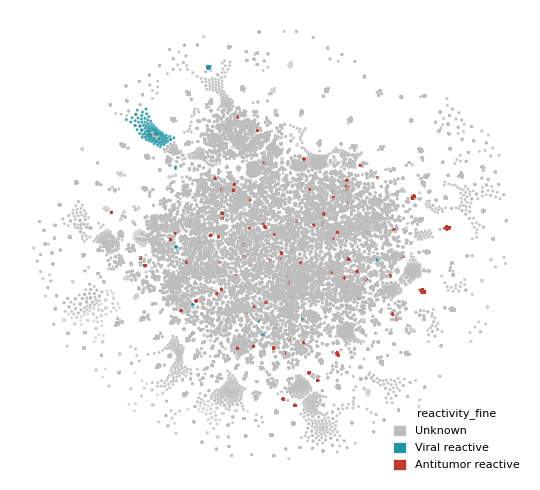

Saved: tsne_specificity.pdf / .png


In [10]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# --- Color palette: biologically meaningful, colorblind-friendly, journal-standard ---
# Gray for unknown, teal for viral, crimson for antitumor
reactivity_fine_colors = {
    '8': '#BDBDBD',   # neutral gray  → Unknown
    '2': '#2196A6',   # deep teal     → Viral reactive
    '1': '#C0392B',   # crimson red   → Antitumor reactive
}

label_map = {
    '8': 'Unknown',
    '2': 'Viral reactive',
    '1': 'Antitumor reactive',
}

# Ensure categorical and set palette order
work_ob.obs['reactivity_fine'] = work_ob.obs['reactivity_fine'].astype(str)
cat_order = ['8', '2', '1']   # plot order: unknown first, then viral, then antitumor
work_ob.obs['reactivity_fine'] = pd.Categorical(
    work_ob.obs['reactivity_fine'], categories=cat_order, ordered=True
)
sc.pl.set_rcParams_defaults()

# --- Figure setup ---
fig, ax = plt.subplots(figsize=(5.5, 5))

sc.pl.tsne(
    work_ob,
    color='reactivity_fine',
    palette=[reactivity_fine_colors[k] for k in cat_order],
    size=18,               # larger dots
    alpha=0.85,
    frameon=False,         # clean look
    legend_loc='none',     # we'll draw a custom legend
    title='',
    ax=ax,
    show=False,
)

# --- Custom legend (publication style) ---
legend_handles = [
    mpatches.Patch(facecolor=reactivity_fine_colors[k],
                   edgecolor='white', linewidth=0.5,
                   label=label_map[k])
    for k in cat_order
]
ax.legend(
    handles=legend_handles,
    title='reactivity_fine',
    title_fontsize=8,
    fontsize=8,
    frameon=False,
    loc='lower right',
    handlelength=1.2,
    handleheight=1.2,
)

# --- Axis labels ---
ax.set_xlabel('t-SNE 1', fontsize=9, labelpad=4)
ax.set_ylabel('t-SNE 2', fontsize=9, labelpad=4)
ax.tick_params(labelsize=7)

# --- Final polish ---
plt.tight_layout()
# saving_prefix_ = 'caushi_2samples'
saving_prefix_ = 'all_samples_withCDR3'
plt.savefig(os.path.join(out_dir,f'tsne_reactivity_fine_{saving_prefix_}.pdf'), dpi=300, bbox_inches='tight', transparent=True)
plt.savefig(os.path.join(out_dir,f'tsne_reactivity_fine_{saving_prefix_}.png'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()
print("Saved: tsne_specificity.pdf / .png")

In [59]:
#sc.pl.tsne(work_ob, color=['sample_detail'])

Top 12 clone sizes:
MD01-005_ASSWSTGGDSPLH     216
MD01-005_ASSSPQGDYEQY       36
MD01-005_ASSLDVAVEQY        23
MD01-005_ASSDPDGGDTGELF     11
MD01-004_ASSFGGNEQF         11
MD01-005_ASSLDLNTEAF        10
ASGQTGTGQQF                  8
MD01-004_ASSWEDRDADTQY       3
MD01-004_ASSVGLGGELF         2
ASSLDAFTDTQY                 2
MD01-005_ASSPSGGDTGELF       1

Highlighting 11 clones
Clone ASGQTGTGQQF: 8 cells
Clone ASSLDAFTDTQY: 2 cells
Clone MD01-004_ASSFGGNEQF: 11 cells
Clone MD01-004_ASSVGLGGELF: 2 cells
Clone MD01-004_ASSWEDRDADTQY: 3 cells
Clone MD01-005_ASSDPDGGDTGELF: 11 cells
Clone MD01-005_ASSLDLNTEAF: 10 cells
Clone MD01-005_ASSLDVAVEQY: 23 cells
Clone MD01-005_ASSPSGGDTGELF: 1 cells
Clone MD01-005_ASSSPQGDYEQY: 36 cells
Clone MD01-005_ASSWSTGGDSPLH: 216 cells


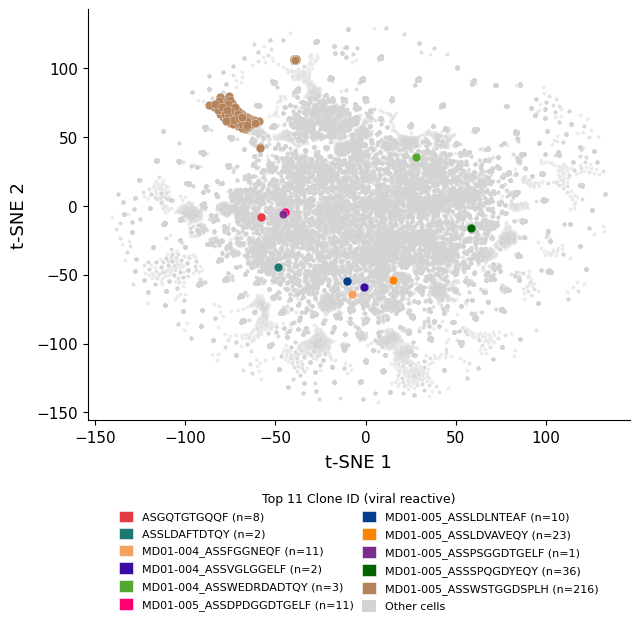

Saved: tsne_clone_highlight.pdf / .png


In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

# --- High-contrast, maximally distinct 11-color palette ---
# Carefully chosen to be distinguishable for colorblind viewers and in print
high_contrast_colors = [
    '#E63946',  # vivid red
    '#1D7874',  # dark teal
    '#F4A261',  # warm orange
    '#3A0CA3',  # deep indigo
    '#55A630',  # strong green
    '#FF006E',  # hot pink/magenta
    '#023E8A',  # navy blue
    '#FB8500',  # amber
    '#7B2D8B',  # purple
    '#006400',  # forest green  
    '#B5835A',  # warm brown
]

# --- Identify clones to highlight ---
mask_highlight = work_ob.obs['reactivity_fine'].astype(str) == '2'

# ── Rank by clone size, keep top 12 ──────────────────────────────────────────
clone_counts = (
    work_ob.obs.loc[mask_highlight, 'sample_clone_id']
    .dropna().astype(str)
    .value_counts()                  # sorted descending by default
)
top12_clones = clone_counts.head(11).index.tolist()
print(f"Top 12 clone sizes:\n{clone_counts.head(11).to_string()}\n")

highlight_clones = sorted(top12_clones)   # sort for consistent color assignment
n_clones = len(highlight_clones)
print(f"Highlighting {n_clones} clones")


clone_color_map = {
    clone: mcolors.to_hex(high_contrast_colors[i % len(high_contrast_colors)])
    for i, clone in enumerate(highlight_clones)
}

# --- Build color array ---
color_arr = np.array(['#D3D3D3'] * len(work_ob), dtype=object)
for clone_id, color in clone_color_map.items():
    mask_clone = (
        mask_highlight.values &
        (work_ob.obs['sample_clone_id'].astype(str).values == str(clone_id))
    )
    color_arr[mask_clone] = mcolors.to_hex(color)

color_col = pd.Series(color_arr, index=work_ob.obs_names)

# --- t-SNE coordinates ---
tsne_coords = work_ob.obsm['X_tsne']
x = tsne_coords[:, 0]
y = tsne_coords[:, 1]
colors = color_col.values

order_bg = np.where(colors == '#D3D3D3')[0]

# --- Figure: wider bottom margin for below-plot legend ---
fig, ax = plt.subplots(figsize=(6.5, 6.5))  # slightly taller for legend space


# Background cells
ax.scatter(x[order_bg], y[order_bg],
           c='#D3D3D3', s=7.5, alpha=0.45,
           linewidths=0, rasterized=True, zorder=1)

# --- Plot each clone, build legend handles only for plotted clones ---
# Convert once outside the loop — pure numpy, no index alignment issues
obs_clone_arr = work_ob.obs['sample_clone_id'].astype(str).values
mask_highlight_arr = (work_ob.obs['reactivity_fine'].astype(str) == '2').values

legend_handles = []
for clone_id, color in clone_color_map.items():
    color_hex = mcolors.to_hex(color)
    
    # Pure numpy boolean — no pandas index involved
    mask_clone = mask_highlight_arr & (obs_clone_arr == str(clone_id))
    idx = np.where(mask_clone)[0]

    print(f"Clone {clone_id}: {len(idx)} cells")  # verify counts

    if len(idx) == 0:
        continue

    ax.scatter(x[idx], y[idx],
               c=color_hex, s=38, alpha=0.95,
               linewidths=0.2, edgecolors='white',
               zorder=2)

    legend_handles.append(
        mpatches.Patch(facecolor=color_hex, edgecolor='white',
                       linewidth=0.4, label=f"{clone_id} (n={len(idx)})")
    )

# Gray entry at the bottom
legend_handles.append(
    mpatches.Patch(facecolor='#D3D3D3', edgecolor='none', label='Other cells')
)

# --- Axes labels & ticks LARGER ---
ax.set_xlabel('t-SNE 1', fontsize=13, labelpad=6)
ax.set_ylabel('t-SNE 2', fontsize=13, labelpad=6)
ax.tick_params(labelsize=11)
ax.spines[['top', 'right']].set_visible(False)

# --- Legend BELOW the plot, 2 columns, larger font ---
legend = ax.legend(
    handles=legend_handles,
    title='Top 11 Clone ID (viral reactive)',
    title_fontsize=9,
    fontsize=8,
    frameon=False,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),   # centered below the axes
    ncol=2,
    handlelength=1.2,
    handleheight=1.2,
    columnspacing=0.8,
    borderpad=0.4,
)

plt.tight_layout()

saving_prefix_ = 'all_samples_withCDR3'
# bbox_inches='tight' ensures legend is not clipped in saved file
plt.savefig(os.path.join(out_dir,f'tsne_reactivity_fine_{saving_prefix_}_2clone_highlight.pdf'), dpi=300, bbox_inches='tight', transparent=True)
plt.savefig(os.path.join(out_dir,f'tsne_reactivity_fine_{saving_prefix_}_2clone_highlight.png'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()
print("Saved: tsne_clone_highlight.pdf / .png")

Top 12 clones by size:
  Rank  1 | MD01-005_ASSWSTGGDSPLH         | n=216
  Rank  2 | MD01-005_ASSSPQGDYEQY          | n=36
  Rank  3 | MD01-005_ASSLDVAVEQY           | n=23
  Rank  4 | MD01-005_ASSDPDGGDTGELF        | n=11
  Rank  5 | MD01-004_ASSFGGNEQF            | n=11
  Rank  6 | MD01-005_ASSLDLNTEAF           | n=10
  Rank  7 | MD01-004_ASSWEDRDADTQY         | n=3
  Rank  8 | MD01-004_ASSVGLGGELF           | n=2
  Rank  9 | MD01-005_ASSPSGGDTGELF         | n=1
  Rank 10 | MD01-005_ASSFDLNTEAF           | n=1
  Rank 11 | MD01-004_SARDRSDEKLF           | n=1

Color assignments:
  MD01-005_ASSWSTGGDSPLH         → #e63946
  MD01-005_ASSSPQGDYEQY          → #1d7874
  MD01-005_ASSLDVAVEQY           → #f4a261
  MD01-005_ASSDPDGGDTGELF        → #3a0ca3
  MD01-004_ASSFGGNEQF            → #55a630
  MD01-005_ASSLDLNTEAF           → #ff006e
  MD01-004_ASSWEDRDADTQY         → #023e8a
  MD01-004_ASSVGLGGELF           → #fb8500
  MD01-005_ASSPSGGDTGELF         → #7b2d8b
  MD01-005_ASSFDLNTEAF  

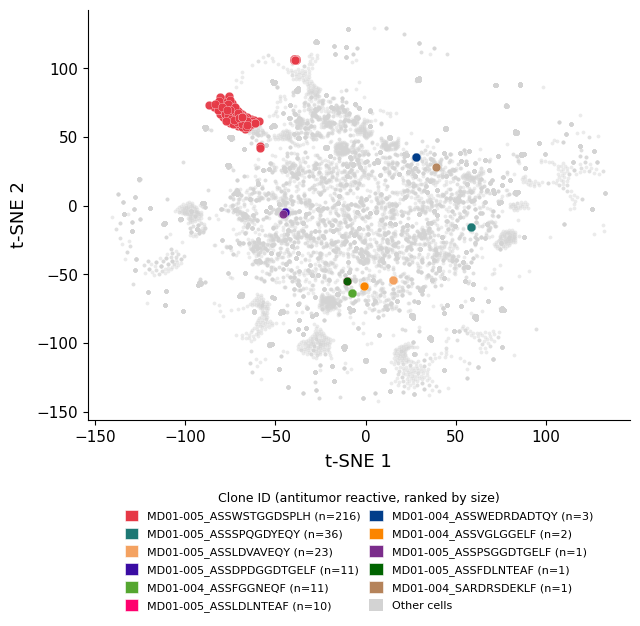

Saved: tsne_clone_highlight.pdf / .png


In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

# --- High-contrast, maximally distinct 11-color palette ---
# Carefully chosen to be distinguishable for colorblind viewers and in print
high_contrast_colors = [
    '#E63946',  # vivid red
    '#1D7874',  # dark teal
    '#F4A261',  # warm orange
    '#3A0CA3',  # deep indigo
    '#55A630',  # strong green
    '#FF006E',  # hot pink/magenta
    '#023E8A',  # navy blue
    '#FB8500',  # amber
    '#7B2D8B',  # purple
    '#006400',  # forest green  
    '#B5835A',  # warm brown
]

# --- Identify clones to highlight ---
mask_highlight = work_ob.obs['reactivity_fine'].astype(str) == '2'

# ── Rank by clone size, keep top 12 ──────────────────────────────────────────
clone_counts = (
    work_ob.obs.loc[mask_highlight, 'sample_clone_id']
    .dropna().astype(str)
    .value_counts()                  # index = clone_id, sorted largest first
)
top12_clones = clone_counts.head(11).index.tolist()  # ordered by size, rank 0 = largest

print("Top 12 clones by size:")
for i, (clone, cnt) in enumerate(clone_counts.head(11).items()):
    print(f"  Rank {i+1:2d} | {clone:30s} | n={cnt}")

# ── Assign colors in size-rank order (rank 1 = color[0]) ─────────────────────
clone_color_map = {
    clone: mcolors.to_hex(high_contrast_colors[i])
    for i, clone in enumerate(top12_clones)   # NO sorted() — preserves size rank
}

# ── Verify mapping ────────────────────────────────────────────────────────────
print("\nColor assignments:")
for clone, color in clone_color_map.items():
    print(f"  {clone:30s} → {color}")

# --- Build color array ---
color_arr = np.array(['#D3D3D3'] * len(work_ob), dtype=object)
obs_clone_arr       = work_ob.obs['sample_clone_id'].astype(str).values
mask_highlight_arr  = (work_ob.obs['reactivity_fine'].astype(str) == '2').values

for clone_id, color in clone_color_map.items():
    mask_clone = mask_highlight_arr & (obs_clone_arr == str(clone_id))
    color_arr[mask_clone] = color

color_col = pd.Series(color_arr, index=work_ob.obs_names)

# --- t-SNE coordinates ---
tsne_coords = work_ob.obsm['X_tsne']
x = tsne_coords[:, 0]
y = tsne_coords[:, 1]
colors = color_col.values

order_bg = np.where(colors == '#D3D3D3')[0]

# --- Figure ---
fig, ax = plt.subplots(figsize=(6.5, 6.5))

# Background cells
ax.scatter(x[order_bg], y[order_bg],
           c='#D3D3D3', s=7.5, alpha=0.45,
           linewidths=0, rasterized=True, zorder=1)

# --- Plot each clone in size-rank order, largest first ---
legend_handles = []
for clone_id, color in clone_color_map.items():
    mask_clone = mask_highlight_arr & (obs_clone_arr == str(clone_id))
    idx = np.where(mask_clone)[0]

    if len(idx) == 0:
        continue

    ax.scatter(x[idx], y[idx],
               c=color, s=38, alpha=0.95,
               linewidths=0.2, edgecolors='white',
               zorder=2)

    legend_handles.append(
        mpatches.Patch(facecolor=color, edgecolor='white', linewidth=0.4,
                       label=f"{clone_id} (n={clone_counts[clone_id]})")  # show true count
    )

# Gray entry at the bottom
legend_handles.append(
    mpatches.Patch(facecolor='#D3D3D3', edgecolor='none', label='Other cells')
)

# --- Axes ---
ax.set_xlabel('t-SNE 1', fontsize=13, labelpad=6)
ax.set_ylabel('t-SNE 2', fontsize=13, labelpad=6)
ax.tick_params(labelsize=11)
ax.spines[['top', 'right']].set_visible(False)

# --- Legend below plot ---
ax.legend(
    handles=legend_handles,
    title='Clone ID (antitumor reactive, ranked by size)',
    title_fontsize=9,
    fontsize=8,
    frameon=False,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    handlelength=1.2,
    handleheight=1.2,
    columnspacing=0.8,
    borderpad=0.4,
)

plt.tight_layout()


# bbox_inches='tight' ensures legend is not clipped in saved file
plt.savefig(os.path.join(out_dir,'tsne_reactivity_fine_caushi_2samples_2clone_highlight.pdf'), dpi=300, bbox_inches='tight', transparent=True)
plt.savefig(os.path.join(out_dir,'tsne_reactivity_fine_caushi_2samples_2clone_highlight.png'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()
print("Saved: tsne_clone_highlight.pdf / .png")

In [ ]:
work_ob[work_ob.obs['sample_clone_id'] == 'MD01-005_ASSWSTGGDSPLH'].obs['sample'].value_counts()

In [23]:
top12_clones

['MD01-005_ASSWSTGGDSPLH',
 'MD01-005_ASSSPQGDYEQY',
 'MD01-005_ASSLDVAVEQY',
 'MD01-005_ASSDPDGGDTGELF',
 'MD01-004_ASSFGGNEQF',
 'MD01-005_ASSLDLNTEAF',
 'MD01-004_ASSWEDRDADTQY',
 'MD01-004_ASSVGLGGELF',
 'MD01-005_ASSPSGGDTGELF',
 'MD01-005_ASSFDLNTEAF',
 'MD01-004_SARDRSDEKLF']

In [24]:
highlight_clones

['MD01-004_ASSFGGNEQF',
 'MD01-004_ASSVGLGGELF',
 'MD01-004_ASSWEDRDADTQY',
 'MD01-004_SARDRSDEKLF',
 'MD01-005_ASSDPDGGDTGELF',
 'MD01-005_ASSFDLNTEAF',
 'MD01-005_ASSLDLNTEAF',
 'MD01-005_ASSLDVAVEQY',
 'MD01-005_ASSPSGGDTGELF',
 'MD01-005_ASSSPQGDYEQY',
 'MD01-005_ASSWSTGGDSPLH']

In [25]:
clone_color_map

{'MD01-004_ASSFGGNEQF': '#e63946',
 'MD01-004_ASSVGLGGELF': '#1d7874',
 'MD01-004_ASSWEDRDADTQY': '#f4a261',
 'MD01-004_SARDRSDEKLF': '#3a0ca3',
 'MD01-005_ASSDPDGGDTGELF': '#55a630',
 'MD01-005_ASSFDLNTEAF': '#ff006e',
 'MD01-005_ASSLDLNTEAF': '#023e8a',
 'MD01-005_ASSLDVAVEQY': '#fb8500',
 'MD01-005_ASSPSGGDTGELF': '#7b2d8b',
 'MD01-005_ASSSPQGDYEQY': '#006400',
 'MD01-005_ASSWSTGGDSPLH': '#b5835a'}

### plot the motif:

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
try:
    import logomaker
    HAS_LOGO = True
except ImportError:
    HAS_LOGO = False
    print("[INFO] logomaker not found — falling back to bar chart. "
          "Install with: pip install logomaker")

# ── Motif / sequence logo ────────────────────────────────────────────────────

AA_LIST = list('ACDEFGHIKLMNPQRSTVWY')


In [29]:
import subprocess
import tempfile
import os
from Bio import AlignIO
from Bio.Align.Applications import MafftCommandline  # pip install biopython

def mafft_align(seqs, mafft_bin='mafft'):
    """
    Align sequences using MAFFT (must be installed: conda install -c bioconda mafft).
    Falls back to center_align() if MAFFT is not available.
    Returns (aligned_seqs, width).
    """
    # Filter valid sequences
    seqs = [s for s in seqs if isinstance(s, str) and s not in ('', 'nan', 'None')]
    if not seqs:
        return [], 0

    # If only one unique length and <=2 seqs, no need to align
    if len(seqs) == 1:
        return seqs, len(seqs[0])

    try:
        # Write sequences to a temp FASTA file
        with tempfile.NamedTemporaryFile(mode='w', suffix='.fasta',
                                         delete=False) as f:
            for i, seq in enumerate(seqs):
                f.write(f'>seq{i}\n{seq}\n')
            tmp_in = f.name

        tmp_out = tmp_in.replace('.fasta', '_aligned.fasta')

        # Run MAFFT
        # --amino     : treat as amino acid
        # --quiet     : suppress progress output
        # --reorder   : reorder output to match input
        # --ep 0      : no end gap penalty (good for CDR3 of varying length)
        cmd = (f'{mafft_bin} --amino --quiet --reorder --ep 0 '
               f'--op 1.5 {tmp_in} > {tmp_out}')
        ret = subprocess.run(cmd, shell=True, capture_output=True)

        if ret.returncode != 0:
            raise RuntimeError(ret.stderr.decode())

        # Parse alignment
        alignment   = AlignIO.read(tmp_out, 'fasta')
        aligned_seqs = [str(rec.seq).upper() for rec in alignment]
        width        = alignment.get_alignment_length()

        print(f"  [MAFFT] Aligned {len(aligned_seqs)} sequences → width {width}")
        return aligned_seqs, width

    except (FileNotFoundError, RuntimeError) as e:
        print(f"  [WARN] MAFFT failed ({e}). Falling back to center_align().")
        return center_align(seqs)

    finally:
        for f in [tmp_in, tmp_out]:
            if os.path.exists(f):
                os.remove(f)


def clustalo_align(seqs, clustalo_bin='clustalo'):
    """
    Alternative: align using Clustal Omega.
    (conda install -c bioconda clustalo)
    """
    seqs = [s for s in seqs if isinstance(s, str) and s not in ('', 'nan', 'None')]
    if not seqs:
        return [], 0

    try:
        with tempfile.NamedTemporaryFile(mode='w', suffix='.fasta',
                                         delete=False) as f:
            for i, seq in enumerate(seqs):
                f.write(f'>seq{i}\n{seq}\n')
            tmp_in = f.name

        tmp_out = tmp_in.replace('.fasta', '_aligned.fasta')

        cmd = (f'{clustalo_bin} -i {tmp_in} -o {tmp_out} '
               f'--outfmt=fasta --force --threads=4')
        ret = subprocess.run(cmd, shell=True, capture_output=True)

        if ret.returncode != 0:
            raise RuntimeError(ret.stderr.decode())

        alignment    = AlignIO.read(tmp_out, 'fasta')
        aligned_seqs = [str(rec.seq).upper() for rec in alignment]
        width        = alignment.get_alignment_length()

        print(f"  [Clustal Omega] Aligned {len(aligned_seqs)} sequences → width {width}")
        return aligned_seqs, width

    except (FileNotFoundError, RuntimeError) as e:
        print(f"  [WARN] Clustal Omega failed ({e}). Falling back to center_align().")
        return center_align(seqs)

    finally:
        for f in [tmp_in, tmp_out]:
            if os.path.exists(f):
                os.remove(f)

/mnt/pixstor/data/lsxgf/miniconda/envs/py-scverse/lib/python3.9/site-packages/Bio/Application/__init__.py:40: BiopythonDeprecationWarning: The Bio.Application modules and modules relying on it have been deprecated.

Due to the on going maintenance burden of keeping command line application
wrappers up to date, we have decided to deprecate and eventually remove these
modules.

We instead now recommend building your command line and invoking it directly
with the subprocess module.
  warnings.warn(


In [30]:
HAS_LOGO

True

## All in one motif plot:

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
try:
    import logomaker
    HAS_LOGO = True
except ImportError:
    HAS_LOGO = False
    print("[INFO] logomaker not found — falling back to bar chart. "
          "Install with: pip install logomaker")

import subprocess
import tempfile
import os
from Bio import AlignIO

# ── Constants ─────────────────────────────────────────────────────────────────
AA_LIST  = list('ACDEFGHIKLMNPQRSTVWY')
CDR3_COL = 'cdr3_aa'

# ── SHARED LAYOUT CONSTANTS (must be identical across both runs) ──────────────
# Set these once by inspecting both groups first, then fix them here.
FIXED_FIG_SIZE   = (18, 5)    # ◀◀ fixed figure size for both runs
FIXED_LOGO_WIDTH = 24         # ◀◀ set to max alignment width across both groups
                               #    (run once per group, take the larger width)
FIXED_BIN_MIN    = 7          # ◀◀ set to min CDR3 length across both groups - 1
FIXED_BIN_MAX    = 22         # ◀◀ set to max CDR3 length across both groups + 2
FIXED_YLIM_LOGO  = None       # ◀◀ optionally fix y-axis of logo, e.g. (0, 4.0)
FIXED_YLIM_HIST  = (0, 0.45)  # ◀◀ fix y-axis of histogram so both match



# ▶▶ Change this to '1', '2', or any other label to switch group ◀◀
REACTIVITY_LABEL = '2'
PREFIX_INPUT = 'cdr3_motif_all_samples_withCDR3' #'cdr3_motif_reactive_caushi_2samples'

REACTIVITY_NAMES = {
    '1': 'antitumor',
    '2': 'viral',
    # add more as needed, e.g. '3': 'autoimmune'
}
REACTIVITY_NAME = REACTIVITY_NAMES.get(REACTIVITY_LABEL, f'reactivity {REACTIVITY_LABEL}')



# ── Matplotlib global style (journal-ready) ───────────────────────────────────
plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size':         11,           # bumped up (was 9)
    'axes.linewidth':    0.8,
    'axes.labelsize':    13,           # bumped up (was 10)
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.labelsize':   10,           # bumped up (was 8)
    'ytick.labelsize':   10,           # bumped up (was 8)
    'pdf.fonttype':      42,
    'ps.fonttype':       42,
})

# ── Alignment helpers ─────────────────────────────────────────────────────────
def center_align(seqs, width=None):
    seqs = [s for s in seqs if isinstance(s, str) and s not in ('', 'nan', 'None')]
    if not seqs:
        return [], 0
    if width is None:
        width = max(len(s) for s in seqs)
    out = []
    for s in seqs:
        pad  = width - len(s)
        left = pad // 2
        out.append('-' * left + s + '-' * (pad - left))
    return out, width

def mafft_align(seqs, mafft_bin='mafft'):
    seqs = [s for s in seqs if isinstance(s, str) and s not in ('', 'nan', 'None')]
    if not seqs:
        return [], 0
    if len(seqs) == 1:
        return seqs, len(seqs[0])
    tmp_in = tmp_out = None
    try:
        with tempfile.NamedTemporaryFile(mode='w', suffix='.fasta', delete=False) as f:
            for i, seq in enumerate(seqs):
                f.write(f'>seq{i}\n{seq}\n')
            tmp_in = f.name
        tmp_out = tmp_in.replace('.fasta', '_aligned.fasta')
        cmd = (f'{mafft_bin} --amino --quiet --reorder --ep 0 '
               f'--op 1.5 {tmp_in} > {tmp_out}')
        ret = subprocess.run(cmd, shell=True, capture_output=True)
        if ret.returncode != 0:
            raise RuntimeError(ret.stderr.decode())
        alignment    = AlignIO.read(tmp_out, 'fasta')
        aligned_seqs = [str(rec.seq).upper() for rec in alignment]
        width        = alignment.get_alignment_length()
        print(f"  [MAFFT] Aligned {len(aligned_seqs)} sequences → width {width}")
        return aligned_seqs, width
    except (FileNotFoundError, RuntimeError) as e:
        print(f"  [WARN] MAFFT failed ({e}). Falling back to center_align().")
        return center_align(seqs)
    finally:
        for f in [tmp_in, tmp_out]:
            if f and os.path.exists(f):
                os.remove(f)

def clustalo_align(seqs, clustalo_bin='clustalo'):
    seqs = [s for s in seqs if isinstance(s, str) and s not in ('', 'nan', 'None')]
    if not seqs:
        return [], 0
    tmp_in = tmp_out = None
    try:
        with tempfile.NamedTemporaryFile(mode='w', suffix='.fasta', delete=False) as f:
            for i, seq in enumerate(seqs):
                f.write(f'>seq{i}\n{seq}\n')
            tmp_in = f.name
        tmp_out = tmp_in.replace('.fasta', '_aligned.fasta')
        cmd = (f'{clustalo_bin} -i {tmp_in} -o {tmp_out} '
               f'--outfmt=fasta --force --threads=4')
        ret = subprocess.run(cmd, shell=True, capture_output=True)
        if ret.returncode != 0:
            raise RuntimeError(ret.stderr.decode())
        alignment    = AlignIO.read(tmp_out, 'fasta')
        aligned_seqs = [str(rec.seq).upper() for rec in alignment]
        width        = alignment.get_alignment_length()
        print(f"  [Clustal Omega] Aligned {len(aligned_seqs)} sequences → width {width}")
        return aligned_seqs, width
    except (FileNotFoundError, RuntimeError) as e:
        print(f"  [WARN] Clustal Omega failed ({e}). Falling back to center_align().")
        return center_align(seqs)
    finally:
        for f in [tmp_in, tmp_out]:
            if f and os.path.exists(f):
                os.remove(f)

# ── Matrix helpers ────────────────────────────────────────────────────────────
def make_freq_df(aligned, width):
    cols    = AA_LIST + ['-']
    counts  = np.zeros((width, len(cols)), dtype=float)
    col_idx = {aa: i for i, aa in enumerate(cols)}
    for seq in aligned:
        for i, aa in enumerate(seq[:width]):
            if aa in col_idx:
                counts[i, col_idx[aa]] += 1
    sums = counts.sum(axis=1, keepdims=True)
    sums[sums == 0] = 1
    return pd.DataFrame(counts / sums, columns=cols)

def information_content(freq_df):
    p = freq_df[AA_LIST].values.clip(1e-9, 1)
    H = -(p * np.log2(p)).sum(axis=1)
    return np.log2(len(AA_LIST)) - H

# ── Extract sequences ─────────────────────────────────────────────────────────
obs = work_ob.obs.copy()
obs['reactivity_fine'] = obs['reactivity_fine'].astype(str)

all_seqs = (obs[CDR3_COL].dropna().astype(str)
            .replace({'nan': None, 'None': None}).dropna().tolist())
all_seqs = [s for s in all_seqs if s]

reactive_obs = obs[obs['reactivity_fine'] == REACTIVITY_LABEL]
react_seqs   = (reactive_obs[CDR3_COL].dropna().astype(str)
                .replace({'nan': None, 'None': None}).dropna().tolist())
react_seqs   = [s for s in react_seqs if s]

print(f"Reactivity group     : '{REACTIVITY_LABEL}' ({REACTIVITY_NAME})")
print(f"Total cells          : {len(obs):,}")
print(f"Reactive cells       : {len(reactive_obs):,}")
print(f"Valid CDR3 (all)     : {len(all_seqs):,}")
print(f"Valid CDR3 (reactive): {len(react_seqs):,}")

if not react_seqs:
    raise ValueError(f"No valid CDR3 sequences found for reactivity == '{REACTIVITY_LABEL}'. "
                     f"Check column '{CDR3_COL}' and reactivity labels.")

lengths = [len(s) for s in react_seqs]
print(f"CDR3 length range    : {min(lengths)}–{max(lengths)} "
      f"(median {int(np.median(lengths))})")

# ── Align & compute matrices ──────────────────────────────────────────────────
aligned, width = mafft_align(react_seqs)
# aligned, width = clustalo_align(react_seqs)
# aligned, width = center_align(react_seqs)

freq_df = make_freq_df(aligned, width)
info    = information_content(freq_df)
print(f"mafft align width: {width}")

# ── Figure layout ─────────────────────────────────────────────────────────────
# ── Pad freq_df and info to FIXED_LOGO_WIDTH if alignment is shorter ──────────
if width < FIXED_LOGO_WIDTH:
    pad_cols = FIXED_LOGO_WIDTH - width
    pad_left  = pad_cols // 2
    pad_right = pad_cols - pad_left
    # Pad with uniform gap rows (all weight on '-')
    gap_row = pd.DataFrame(
        [[0.0] * len(AA_LIST) + [1.0]] * 1,
        columns=AA_LIST + ['-']
    )
    freq_df = pd.concat(
        [gap_row] * pad_left + [freq_df] + [gap_row] * pad_right,
        ignore_index=True
    )
    info = np.concatenate([
        np.zeros(pad_left), info, np.zeros(pad_right)
    ])
    width = FIXED_LOGO_WIDTH
    print(f"  Padded alignment to fixed width {FIXED_LOGO_WIDTH}")


# ── Figure layout — fixed size ────────────────────────────────────────────────
fig, (ax_logo, ax_len) = plt.subplots(
    1, 2,
    figsize=FIXED_FIG_SIZE,            # ◀◀ fixed, not data-dependent
    gridspec_kw={
        'width_ratios': [2, 1],
        'wspace': 0.18,
    }
)


# ── Panel 1 — Sequence logo ───────────────────────────────────────────────────
if HAS_LOGO:
    logo_df = freq_df[AA_LIST].multiply(info, axis=0).clip(lower=0)
    logo = logomaker.Logo(
        logo_df,
        ax=ax_logo,
        color_scheme='chemistry',
        vpad=0.05,
        width=0.9,
        font_name='DejaVu Sans',
    )
    logo.style_spines(visible=False)
    logo.style_spines(spines=['left', 'bottom'], visible=True)
    ax_logo.yaxis.set_major_locator(ticker.MaxNLocator(4))
    ax_logo.set_ylabel('Bits', fontsize=13)
else:
    chem_colors = {
        'KRH': '#4878CF', 'DE': '#D65F5F', 'STNQ': '#6ACC65',
        'CM':  '#B47CC7', 'FYW': '#C4AD66', 'AVILPG': '#777777',
    }
    aa_to_color = {aa: col for group, col in chem_colors.items() for aa in group}
    bottoms = np.zeros(width)
    for aa in AA_LIST:
        heights = freq_df[aa].values * info
        ax_logo.bar(range(width), heights, bottom=bottoms,
                    color=aa_to_color.get(aa, '#AAAAAA'),
                    width=0.85, linewidth=0)
        bottoms += heights
    ax_logo.set_ylabel('Bits', fontsize=13)
    ax_logo.spines[['top', 'right']].set_visible(False)

ax_logo.set_xlabel('Position', fontsize=13)
ax_logo.set_xlim(-0.5, FIXED_LOGO_WIDTH - 0.5)      # ◀◀ fixed x range
ax_logo.set_xticks(range(FIXED_LOGO_WIDTH))
ax_logo.set_xticklabels([str(i + 1) for i in range(FIXED_LOGO_WIDTH)], fontsize=10)
ax_logo.tick_params(axis='y', labelsize=10)
if FIXED_YLIM_LOGO is not None:
    ax_logo.set_ylim(FIXED_YLIM_LOGO)               # ◀◀ fixed y range (optional)
ax_logo.set_title(
    f"CDR3 sequence motif — {REACTIVITY_NAME} reactive T cells   "
    f"(n = {len(aligned):,} sequences)",
    fontsize=14, fontweight='bold', pad=8)

# ── Panel 2 — CDR3 length distribution ───────────────────────────────────────
bins = np.arange(FIXED_BIN_MIN, FIXED_BIN_MAX + 1, 1)   # ◀◀ fixed bins
ax_len.hist([len(s) for s in all_seqs],
            bins=bins, alpha=0.55, color='#5688C7',
            label=f'All  (n={len(all_seqs):,})', density=True,
            linewidth=0.4, edgecolor='white')
ax_len.hist([len(s) for s in react_seqs],
            bins=bins, alpha=0.80, color='#C0392B',
            label=f"{REACTIVITY_NAME} (n={len(react_seqs):,})",
            density=True, linewidth=0.4, edgecolor='white')
ax_len.set_xlabel('CDR3 length (aa)', fontsize=13)
ax_len.set_ylabel('Density',          fontsize=13)
ax_len.set_title('CDR3 length distribution', fontsize=14, fontweight='bold', pad=12)
ax_len.set_xlim(FIXED_BIN_MIN, FIXED_BIN_MAX)            # ◀◀ fixed x range
ax_len.set_ylim(FIXED_YLIM_HIST)                          # ◀◀ fixed y range
ax_len.legend(
    frameon=False, fontsize=12,
    bbox_to_anchor=(1.15, 1.0),
    loc='upper right',
    borderaxespad=0,
)
ax_len.spines[['top', 'right']].set_visible(False)
ax_len.yaxis.set_major_locator(ticker.MaxNLocator(4))
ax_len.tick_params(axis='both', labelsize=10)



# ── Save ─────────────────────────────────────────────────────────────────────
tag = REACTIVITY_NAME
plt.show()
prefix_ = PREFIX_INPUT #'cdr3_motif_reactive_caushi_2samples'
plt.savefig(os.path.join(out_dir, f'{prefix_}_motif_{tag}.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.savefig(os.path.join(out_dir, f'{prefix_}_motif_{tag}.png'),
            dpi=300, bbox_inches='tight', transparent=True)

print(f"\nSaved: cdr3_motif_{tag}.pdf / .png")

freq_df.to_csv(os.path.join(out_dir, f'{prefix_}_pfm_cdr3_{tag}.csv'), index_label='position')
print(f"Saved: pfm_cdr3_{tag}.csv")

Reactivity group     : '2' (viral)
Total cells          : 59,441
Reactive cells       : 327
Valid CDR3 (all)     : 59,441
Valid CDR3 (reactive): 327
CDR3 length range    : 10–15 (median 13)
  [MAFFT] Aligned 327 sequences → width 17
mafft align width: 17
  Padded alignment to fixed width 24

Saved: cdr3_motif_viral.pdf / .png
Saved: pfm_cdr3_viral.csv


In [50]:
np.arange(bin_min, bin_max + 1, 1)

array([ 6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22])

Group '1' (antitumor): 2,536 sequences
Group '2' (viral): 327 sequences
  [MAFFT] 2863 sequences → width 32
Joint alignment width: 32
  Group '1': 2,536 seqs, width 32
  Group '2': 327 seqs, width 32

Saved: cdr3_motif_all_samples_withCDR3_motif_combined.pdf / .png
Saved: pfm_cdr3_antitumor.csv
Saved: pfm_cdr3_viral.csv


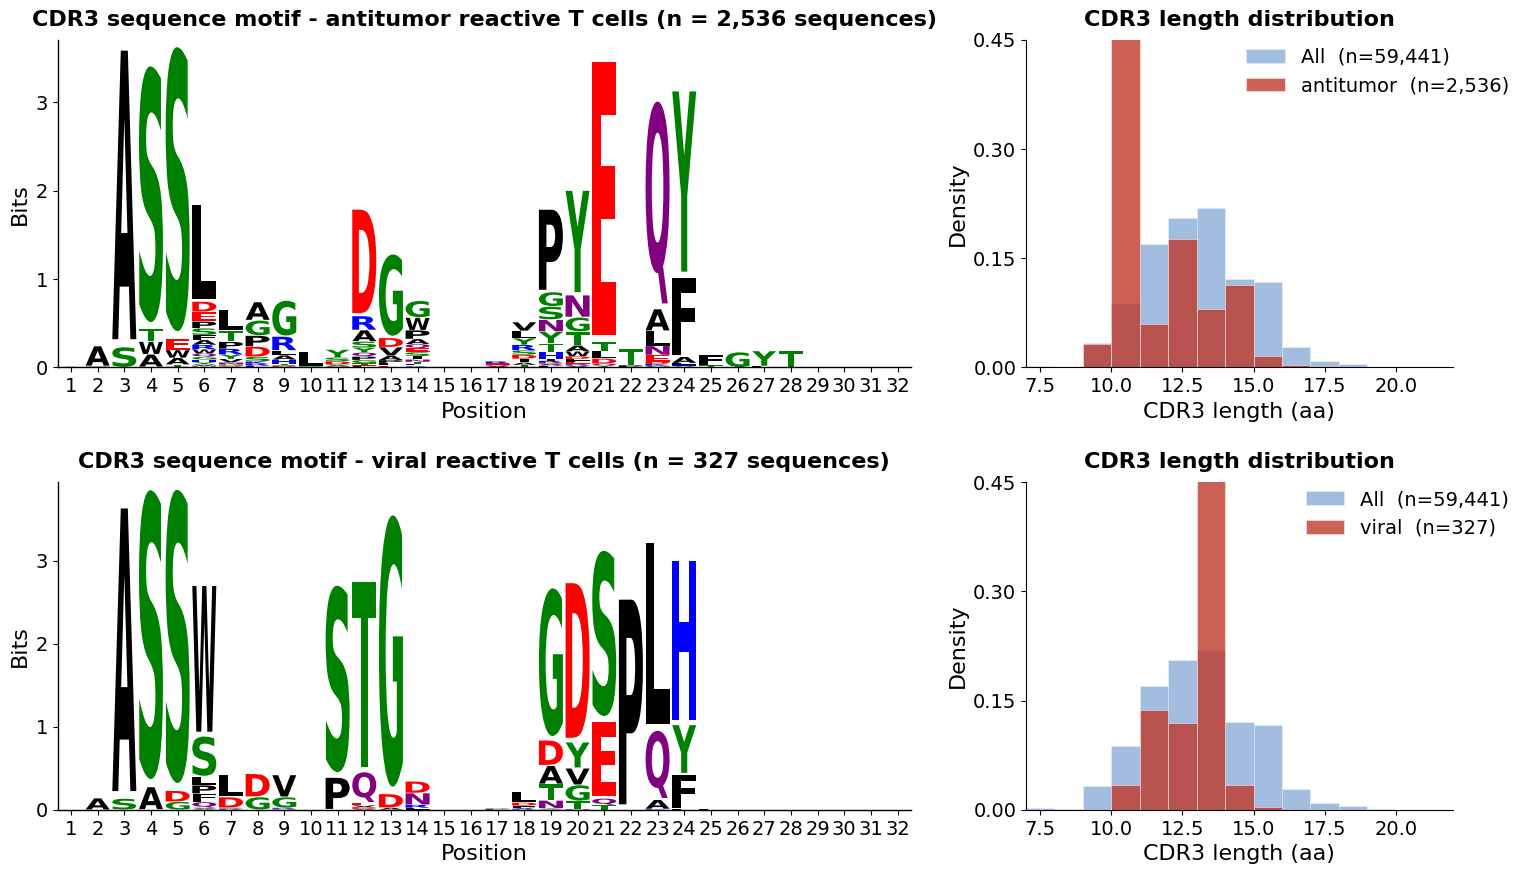

In [11]:
# 20260712
# All in one plot, align together then plot motfi individually:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
try:
    import logomaker
    HAS_LOGO = True
except ImportError:
    HAS_LOGO = False

import subprocess
import tempfile
import os
from Bio import AlignIO

# ── Constants ─────────────────────────────────────────────────────────────────
AA_LIST  = list('ACDEFGHIKLMNPQRSTVWY')
CDR3_COL = 'cdr3_aa'
PREFIX_INPUT = 'cdr3_motif_all_samples_withCDR3'

REACTIVITY_LABELS = ['1', '2']
REACTIVITY_NAMES  = {'1': 'antitumor', '2': 'viral'}

# ── SHARED LAYOUT CONSTANTS ───────────────────────────────────────────────────
FIXED_FIG_SIZE  = (18, 10)     # total figure: 2 rows
FIXED_BIN_MIN   = 7
FIXED_BIN_MAX   = 22
FIXED_YLIM_HIST = (0, 0.45)
FIXED_YLIM_LOGO = None         # e.g. (0, 4.0) to fix y-axis across rows

# ── Matplotlib global style ───────────────────────────────────────────────────
plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size':         11,
    'axes.linewidth':    0.8,
    'axes.labelsize':    13,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.labelsize':   10,
    'ytick.labelsize':   10,
    'pdf.fonttype':      42,
    'ps.fonttype':       42,
})

# ── Helpers ───────────────────────────────────────────────────────────────────
def clean_seqs(series):
    return [s for s in series.dropna().astype(str)
            .replace({'nan': None, 'None': None}).dropna().tolist()
            if s]

def mafft_align(seqs, mafft_bin='mafft'):
    seqs = [s for s in seqs if isinstance(s, str) and s not in ('', 'nan', 'None')]
    if not seqs:
        return [], 0
    if len(seqs) == 1:
        return seqs, len(seqs[0])
    tmp_in = tmp_out = None
    try:
        with tempfile.NamedTemporaryFile(mode='w', suffix='.fasta', delete=False) as f:
            for i, seq in enumerate(seqs):
                f.write(f'>seq{i}\n{seq}\n')
            tmp_in = f.name
        tmp_out = tmp_in.replace('.fasta', '_aligned.fasta')
        cmd = (f'{mafft_bin} --amino --quiet --ep 0 '
               f'--op 1.5 {tmp_in} > {tmp_out}')
        ret = subprocess.run(cmd, shell=True, capture_output=True)
        if ret.returncode != 0:
            raise RuntimeError(ret.stderr.decode())
        alignment    = AlignIO.read(tmp_out, 'fasta')
        aligned_seqs = [str(rec.seq).upper() for rec in alignment]
        width        = alignment.get_alignment_length()
        print(f"  [MAFFT] {len(aligned_seqs)} sequences → width {width}")
        return aligned_seqs, width
    except (FileNotFoundError, RuntimeError) as e:
        print(f"  [WARN] MAFFT failed ({e}). Falling back to center_align().")
        return center_align(seqs)
    finally:
        for f in [tmp_in, tmp_out]:
            if f and os.path.exists(f):
                os.remove(f)

def center_align(seqs, width=None):
    seqs = [s for s in seqs if isinstance(s, str) and s not in ('', 'nan', 'None')]
    if not seqs:
        return [], 0
    if width is None:
        width = max(len(s) for s in seqs)
    out = []
    for s in seqs:
        pad  = width - len(s)
        left = pad // 2
        out.append('-' * left + s + '-' * (pad - left))
    return out, width

def center_align_to_width(seqs, target_width):
    """Center-pad a list of already-clean seqs to a fixed target_width."""
    out = []
    for s in seqs:
        pad   = target_width - len(s)
        left  = pad // 2
        right = pad - left
        out.append('-' * left + s + '-' * right)
    return out

def make_freq_df(aligned, width):
    cols    = AA_LIST + ['-']
    counts  = np.zeros((width, len(cols)), dtype=float)
    col_idx = {aa: i for i, aa in enumerate(cols)}
    for seq in aligned:
        for i, aa in enumerate(seq[:width]):
            if aa in col_idx:
                counts[i, col_idx[aa]] += 1
    sums = counts.sum(axis=1, keepdims=True)
    sums[sums == 0] = 1
    return pd.DataFrame(counts / sums, columns=cols)

def information_content(freq_df):
    p = freq_df[AA_LIST].values.clip(1e-9, 1)
    H = -(p * np.log2(p)).sum(axis=1)
    return np.log2(len(AA_LIST)) - H

# ── Step 1: Extract sequences per group ───────────────────────────────────────
obs = work_ob.obs.copy()
obs['reactivity_fine'] = obs['reactivity_fine'].astype(str)

all_seqs = clean_seqs(obs[CDR3_COL])

group_seqs = {}   # raw (unaligned) sequences per group
for label in REACTIVITY_LABELS:
    sub = obs[obs['reactivity_fine'] == label]
    seqs = clean_seqs(sub[CDR3_COL])
    group_seqs[label] = seqs
    print(f"Group '{label}' ({REACTIVITY_NAMES[label]}): {len(seqs):,} sequences")

# ── Step 2: Joint alignment ───────────────────────────────────────────────────
tagged    = []
group_tag = []
for label in REACTIVITY_LABELS:
    for s in group_seqs[label]:
        tagged.append(s)
        group_tag.append(label)

joint_aligned, FIXED_LOGO_WIDTH = mafft_align(tagged)
print(f"Joint alignment width: {FIXED_LOGO_WIDTH}")

# ── Step 3: Split aligned sequences back by group — safe without --reorder ────
per_group_aligned = {}
idx = 0
for label in REACTIVITY_LABELS:
    n = len(group_seqs[label])
    per_group_aligned[label] = joint_aligned[idx: idx + n]   # ◀◀ direct slice
    idx += n
    print(f"  Group '{label}': {len(per_group_aligned[label]):,} seqs, "
          f"width {FIXED_LOGO_WIDTH}")

# ── Step 4: Compute freq_df and info per group — unchanged ───────────────────
per_group_freq = {}
per_group_info = {}
for label in REACTIVITY_LABELS:
    freq_df = make_freq_df(per_group_aligned[label], FIXED_LOGO_WIDTH)
    info    = information_content(freq_df)
    per_group_freq[label] = freq_df
    per_group_info[label] = info


# ── Step 5: Plot — 2 rows × 2 cols ───────────────────────────────────────────
fig, axes = plt.subplots(
    2, 2,
    figsize=FIXED_FIG_SIZE,
    gridspec_kw={
        'width_ratios': [2, 1],
        'wspace': 0.18,
        'hspace': 0.35,
    }
)

bins = np.arange(FIXED_BIN_MIN, FIXED_BIN_MAX + 1, 1)

for row_idx, label in enumerate(REACTIVITY_LABELS):
    name    = REACTIVITY_NAMES[label]
    freq_df = per_group_freq[label]
    info    = per_group_info[label]
    aligned = per_group_aligned[label]
    react_seqs = group_seqs[label]

    ax_logo = axes[row_idx, 0]
    ax_len  = axes[row_idx, 1]

    # ── Logo panel ────────────────────────────────────────────────────────────
    if HAS_LOGO:
        logo_df = freq_df[AA_LIST].multiply(info, axis=0).clip(lower=0)
        logo = logomaker.Logo(
            logo_df,
            ax=ax_logo,
            color_scheme='chemistry',
            vpad=0.05,
            width=0.9,
            font_name='DejaVu Sans',
        )
        logo.style_spines(visible=False)
        logo.style_spines(spines=['left', 'bottom'], visible=True)
        ax_logo.yaxis.set_major_locator(ticker.MaxNLocator(4))
        ax_logo.set_ylabel('Bits', fontsize=16)
        ax_logo.set_xlabel('Position', fontsize=16)
    else:
        chem_colors = {
            'KRH': '#4878CF', 'DE': '#D65F5F', 'STNQ': '#6ACC65',
            'CM':  '#B47CC7', 'FYW': '#C4AD66', 'AVILPG': '#777777',
        }
        aa_to_color = {aa: col for group, col in chem_colors.items() for aa in group}
        bottoms = np.zeros(FIXED_LOGO_WIDTH)
        for aa in AA_LIST:
            heights = freq_df[aa].values * info
            ax_logo.bar(range(FIXED_LOGO_WIDTH), heights, bottom=bottoms,
                        color=aa_to_color.get(aa, '#AAAAAA'),
                        width=0.85, linewidth=0)
            bottoms += heights
        ax_logo.set_ylabel('Bits', fontsize=13)
        ax_logo.spines[['top', 'right']].set_visible(False)

    ax_logo.set_xlim(-0.5, FIXED_LOGO_WIDTH - 0.5)
    ax_logo.set_xticks(range(FIXED_LOGO_WIDTH))
    ax_logo.set_xticklabels([str(i + 1) for i in range(FIXED_LOGO_WIDTH)], fontsize=14)
    ax_logo.tick_params(axis='y', labelsize=14)
    if FIXED_YLIM_LOGO is not None:
        ax_logo.set_ylim(FIXED_YLIM_LOGO)
    ax_logo.set_xlabel('Position', fontsize=16)
    ax_logo.set_title(
        f"CDR3 sequence motif - {name} reactive T cells "
        f"(n = {len(aligned):,} sequences)",
        fontsize=16, fontweight='bold', pad=10)

    # ── Length distribution panel ─────────────────────────────────────────────
    ax_len.hist([len(s) for s in all_seqs],
                bins=bins, alpha=0.55, color='#5688C7',
                label=f'All  (n={len(all_seqs):,})', density=True,
                linewidth=0.4, edgecolor='white')
    ax_len.hist([len(s) for s in react_seqs],
                bins=bins, alpha=0.80, color='#C0392B',
                label=f"{name}  (n={len(react_seqs):,})",
                density=True, linewidth=0.4, edgecolor='white')
    ax_len.set_xlabel('CDR3 length (aa)', fontsize=16)
    ax_len.set_ylabel('Density',          fontsize=16)
    ax_len.set_title('CDR3 length distribution', fontsize=16,
                     fontweight='bold', pad=10)
    ax_len.set_xlim(FIXED_BIN_MIN, FIXED_BIN_MAX)
    ax_len.set_ylim(FIXED_YLIM_HIST)
    ax_len.legend(
        frameon=False, fontsize=14,
        bbox_to_anchor=(1.15, 1.0),
        loc='upper right',
        borderaxespad=0,
    )
    ax_len.spines[['top', 'right']].set_visible(False)
    ax_len.yaxis.set_major_locator(ticker.MaxNLocator(4))
    ax_len.tick_params(axis='both', labelsize=14)

# ── Save ──────────────────────────────────────────────────────────────────────
#plt.show()
plt.savefig(os.path.join(out_dir, f'{PREFIX_INPUT}_motif_12_combined.pdf'),
            dpi=300, bbox_inches='tight', transparent=True)
plt.savefig(os.path.join(out_dir, f'{PREFIX_INPUT}_motif_12_combined.png'),
            dpi=300, bbox_inches='tight', transparent=True)
print(f"\nSaved: {PREFIX_INPUT}_motif_combined.pdf / .png")

# ── Export per-group PFM ──────────────────────────────────────────────────────
for label in REACTIVITY_LABELS:
    name = REACTIVITY_NAMES[label]
    per_group_freq[label].to_csv(
        os.path.join(out_dir, f'{PREFIX_INPUT}_pfm_cdr3_{name}.csv'),
        index_label='position')
    print(f"Saved: pfm_cdr3_{name}.csv")



In [7]:
HAS_LOGO

True

In [10]:
out_dir

'/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/visualize_esm2_embedding_motif'